In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Cargar los datos
df = pd.read_csv("data/country_data.csv")

# Ver las primeras filas
display(df.head(10))

,country,child_mort,exports,health,imports,income,inflation,life_expect,total_fert,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.440,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.490,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.100,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.440,76.8,2.13,12200
5,Argentina,14.5,18.9,8.10,16.0,18700,20.900,75.8,2.37,10300
6,Armenia,18.1,20.8,4.40,45.3,6700,7.770,73.3,1.69,3220
7,Australia,4.8,19.8,8.73,20.9,41400,1.160,82.0,1.93,51900
8,Austria,4.3,51.3,11.00,47.8,43200,0.873,80.5,1.44,46900
9,Azerbaijan,39.2,54.3,5.88,20.7,16000,13.800,69.1,1.92,5840


In [2]:
df.info()
display(df.describe())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      167 non-null    str    
 1   child_mort   167 non-null    float64
 2   exports      167 non-null    float64
 3   health       167 non-null    float64
 4   imports      167 non-null    float64
 5   income       167 non-null    int64  
 6   inflation    167 non-null    float64
 7   life_expect  167 non-null    float64
 8   total_fert   167 non-null    float64
 9   gdpp         167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


,child_mort,exports,health,imports,income,inflation,life_expect,total_fert,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


country        0
child_mort     0
exports        0
health         0
imports        0
income         0
inflation      0
life_expect    0
total_fert     0
gdpp           0
dtype: int64


In [3]:
# Variables para el clustering
X = df[["child_mort", "gdpp"]].values
X[:10]

array([[9.02e+01, 5.53e+02],
       [1.66e+01, 4.09e+03],
       [2.73e+01, 4.46e+03],
       [1.19e+02, 3.53e+03],
       [1.03e+01, 1.22e+04],
       [1.45e+01, 1.03e+04],
       [1.81e+01, 3.22e+03],
       [4.80e+00, 5.19e+04],
       [4.30e+00, 4.69e+04],
       [3.92e+01, 5.84e+03]])

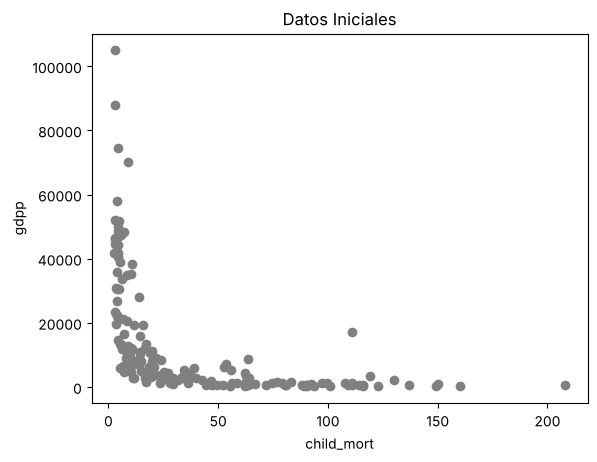

In [4]:
# Visualizar los datos iniciales
plt.scatter(X[:, 0], X[:, 1], color='gray')
plt.title("Datos Iniciales")
plt.xlabel("child_mort")
plt.ylabel("gdpp")
plt.savefig("imagenes/01_datos_iniciales.png", dpi=150, bbox_inches="tight")
plt.show()

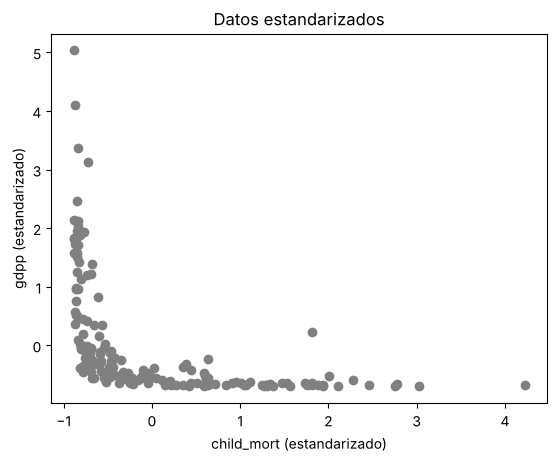

In [5]:
# Las variables tienen escalas muy distintas, se estandarizan
scaler = StandardScaler()
X_esc = scaler.fit_transform(X)

plt.scatter(X_esc[:, 0], X_esc[:, 1], color='gray')
plt.title("Datos estandarizados")
plt.xlabel("child_mort (estandarizado)")
plt.ylabel("gdpp (estandarizado)")
plt.show()

K-Means con sklearn

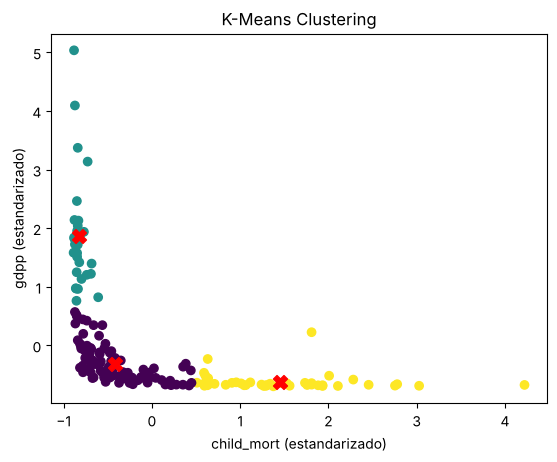

In [6]:
# Crear un modelo K-Means
model = KMeans(n_clusters=3, n_init=10, random_state=42)

# Entrenar el modelo
model.fit(X_esc)

# Obtener las etiquetas de los clusters y los centroides
labels = model.labels_
centroids = model.cluster_centers_

# Visualizar los resultados
plt.scatter(X_esc[:, 0], X_esc[:, 1], c=labels, cmap='viridis')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=100)
plt.xlabel('child_mort (estandarizado)')
plt.ylabel('gdpp (estandarizado)')
plt.title('K-Means Clustering')
plt.savefig("imagenes/02_kmeans_sklearn.png", dpi=150, bbox_inches="tight")
plt.show()

K-means paso a paso

In [7]:
def distancia_euclidiana(punto1, punto2):
    return np.sqrt(np.sum((punto1 - punto2) ** 2))

In [8]:
def inicializar_centroides(data, k):
    indices = np.random.choice(len(data), k, replace=False)
    centroides = data[indices]
    return centroides

In [9]:
def asignar_clusters(data, centroides):
    clusters = []
    for punto in data:
        distancias = [distancia_euclidiana(punto, centroide) for centroide in centroides]
        cluster = np.argmin(distancias)
        clusters.append(cluster)
    return np.array(clusters)

In [10]:
def actualizar_centroides(data, clusters, k):
    nuevos_centroides = []
    for i in range(k):
        puntos_cluster = data[clusters == i]
        if len(puntos_cluster) > 0:
            nuevo_centroide = puntos_cluster.mean(axis=0)
        else:
            nuevo_centroide = data[np.random.choice(len(data))]
        nuevos_centroides.append(nuevo_centroide)
    return np.array(nuevos_centroides)

In [11]:
def k_means(data, k, max_iters=10):
    centroides = inicializar_centroides(data, k)
    for iteracion in range(max_iters):
        # Asignar clusters a cada punto
        clusters = asignar_clusters(data, centroides)

        # Visualizar el estado actual
        plt.figure()
        colores = ['red', 'blue', 'green', 'purple', 'orange']
        for i in range(k):
            puntos_cluster = data[clusters == i]
            plt.scatter(puntos_cluster[:, 0], puntos_cluster[:, 1], color=colores[i], label=f"Cluster {i+1}")
        plt.scatter(centroides[:, 0], centroides[:, 1], color='black', marker='x', s=100, label="Centroides")
        plt.title(f"Iteración {iteracion + 1}")
        plt.xlabel("child_mort (estandarizado)")
        plt.ylabel("gdpp (estandarizado)")
        plt.legend()
        plt.show()

        # Calcular nuevos centroides
        nuevos_centroides = actualizar_centroides(data, clusters, k)

        # Comprobar si los centroides han cambiado
        if np.all(centroides == nuevos_centroides):
            print(f"Convergencia alcanzada en la iteración {iteracion + 1}")
            break
        centroides = nuevos_centroides
    return clusters, centroides

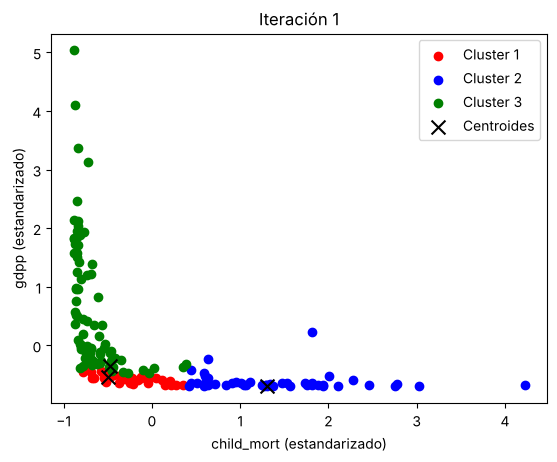

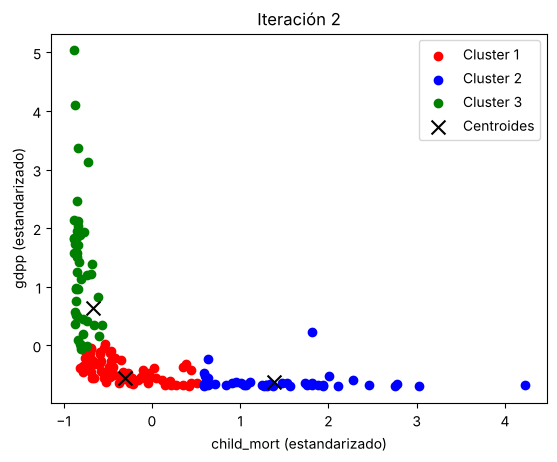

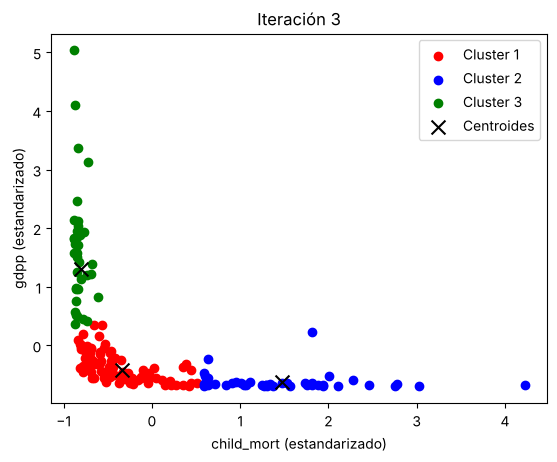

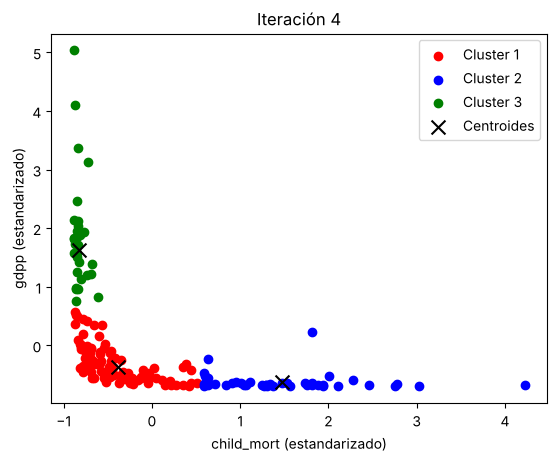

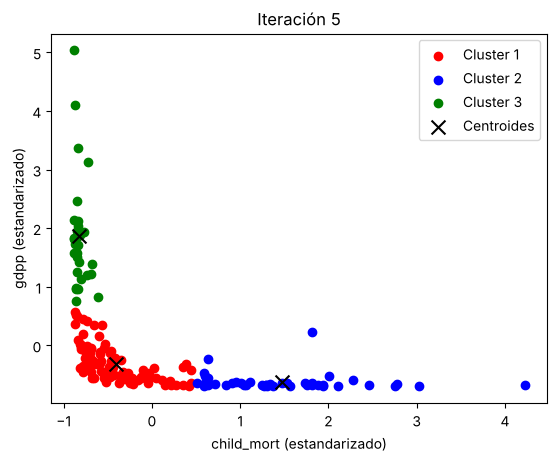

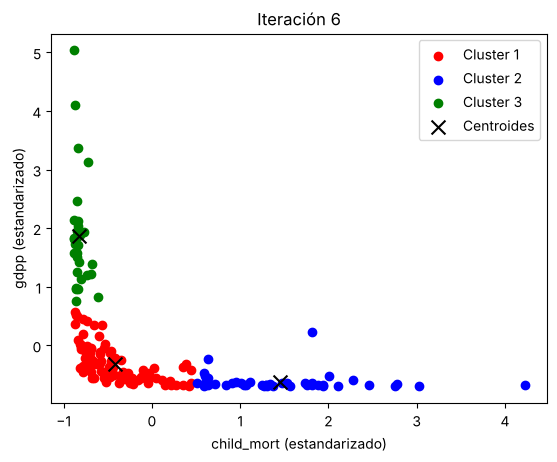

Convergencia alcanzada en la iteración 6


In [12]:
# Definir el número de clusters
k = 3
np.random.seed(6)

# Ejecutar el algoritmo K-Means y visualizar cada paso
clusters_manual, centroides_manual = k_means(X_esc, k)

Inercia y método del codo

In [13]:
def calcular_inercia(data, centroides, clusters):
    inercia = 0.0
    for i, centroide in enumerate(centroides):
        puntos_cluster = data[clusters == i]
        inercia += np.sum((puntos_cluster - centroide) ** 2)
    return inercia

In [14]:
def calcular_inercia_para_k(data, max_k=10, max_iters=50, n_intentos=10):
    inercia_valores = []
    for k in range(1, max_k + 1):
        mejor_inercia = np.inf
        # Se repite varias veces porque los centroides iniciales son aleatorios
        for _ in range(n_intentos):
            # Inicializar centroides aleatoriamente
            centroides = inicializar_centroides(data, k)

            for _ in range(max_iters):
                # Asignar clusters
                clusters = asignar_clusters(data, centroides)

                # Actualizar centroides
                nuevos_centroides = actualizar_centroides(data, clusters, k)

                # Comprobar si los centroides han cambiado
                if np.all(centroides == nuevos_centroides):
                    break
                centroides = nuevos_centroides

            # Calcular inercia y quedarse con la menor
            inercia = calcular_inercia(data, centroides, clusters)
            mejor_inercia = min(mejor_inercia, inercia)

        inercia_valores.append(mejor_inercia)
        print(f"K={k}, Inercia={mejor_inercia}")
    return inercia_valores

K=1, Inercia=334.0
K=2, Inercia=180.5027352520749


K=3, Inercia=75.09226458684589


K=4, Inercia=53.7627231239178


K=5, Inercia=40.128758464523756


K=6, Inercia=26.78336597658511


K=7, Inercia=19.84432215027463


K=8, Inercia=16.191153877520613


K=9, Inercia=14.230494698816182


K=10, Inercia=11.842467783008045


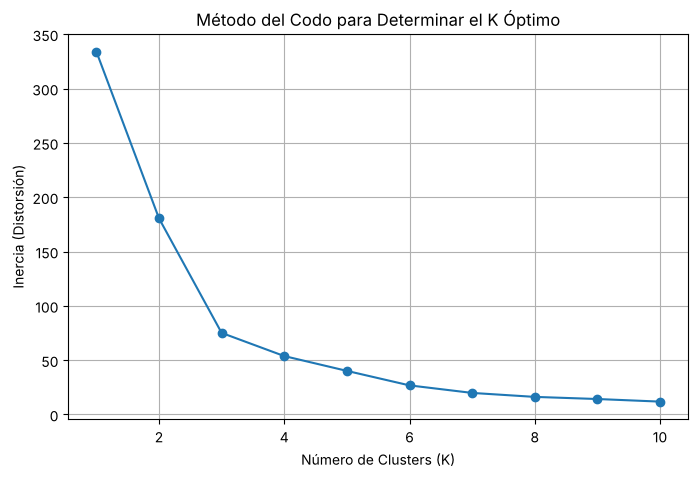

In [15]:
# Implementar el método del codo
np.random.seed(42)
max_k = 10
inercia_valores = calcular_inercia_para_k(X_esc, max_k=max_k)

# Graficar inercia vs. K
plt.figure(figsize=(8, 5))
plt.plot(range(1, max_k + 1), inercia_valores, marker='o')
plt.xlabel("Número de Clusters (K)")
plt.ylabel("Inercia (Distorsión)")
plt.title("Método del Codo para Determinar el K Óptimo")
plt.grid(True)
plt.savefig("imagenes/03_metodo_codo.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# Comparar con sklearn: inercia y coeficiente de silueta
inercia_sk, silueta_sk = [], []
for k in range(1, 11):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_esc)
    inercia_sk.append(m.inertia_)
    silueta_sk.append(silhouette_score(X_esc, m.labels_) if k > 1 else np.nan)

resumen_k = pd.DataFrame({
    "K": range(1, 11),
    "Inercia (propia)": np.round(inercia_valores, 2),
    "Inercia (sklearn)": np.round(inercia_sk, 2),
    "Silueta": np.round(silueta_sk, 3)
})
display(resumen_k)

,K,Inercia (propia),Inercia (sklearn),Silueta
0,1,334.00,334.00,NaN
1,2,180.50,180.50,0.527
2,3,75.09,75.09,0.589
3,4,53.76,53.76,0.550
4,5,40.13,34.63,0.565
5,6,26.78,26.78,0.498
6,7,19.84,19.79,0.505
7,8,16.19,16.07,0.478
8,9,14.23,13.74,0.468
9,10,11.84,11.47,0.472


In [17]:
print("Inercia propia (K=3):  ", round(calcular_inercia(X_esc, centroides_manual, clusters_manual), 3))
print("Inercia sklearn (K=3): ", round(model.inertia_, 3))
print("Silueta sklearn (K=3): ", round(silhouette_score(X_esc, labels), 3))

Inercia propia (K=3):   75.092
Inercia sklearn (K=3):  75.092
Silueta sklearn (K=3):  0.589


Interpretación de los clusters

In [18]:
# Agregar el cluster a cada país
df["Cluster"] = labels

perfil = df.groupby("Cluster").agg(
    Paises=("country", "count"),
    child_mort=("child_mort", "mean"),
    gdpp=("gdpp", "mean"),
    income=("income", "mean"),
    life_expect=("life_expect", "mean"),
    total_fert=("total_fert", "mean")
).round(1)
display(perfil)

,Paises,child_mort,gdpp,income,life_expect,total_fert
Cluster,,,,,,
0,93,21.4,7326.8,13486.7,72.7,2.3
1,30,5.2,47053.3,48596.7,80.3,1.8
2,44,96.4,1636.8,3431.9,59.5,5.0


In [19]:
# Nombrar los grupos ordenando por mortalidad infantil promedio
orden = perfil["child_mort"].sort_values().index
nombres = {orden[0]: "Alto desarrollo", orden[1]: "Desarrollo medio", orden[2]: "Prioridad de ayuda"}
df["Grupo"] = df["Cluster"].map(nombres)

for grupo in ["Alto desarrollo", "Desarrollo medio", "Prioridad de ayuda"]:
    paises = df[df["Grupo"] == grupo]["country"].tolist()
    print(f"{grupo} ({len(paises)}): {paises[:10]}")

# Países de la región
display(df[df["country"].isin(["Peru", "Colombia", "Chile", "Brazil", "Bolivia"])][["country", "child_mort", "gdpp", "Grupo"]])

Alto desarrollo (30): ['Australia', 'Austria', 'Bahamas', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Finland', 'France']
Desarrollo medio (93): ['Albania', 'Algeria', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus']
Prioridad de ayuda (44): ['Afghanistan', 'Angola', 'Benin', 'Burkina Faso', 'Burundi', 'Cameroon', 'Central African Republic', 'Chad', 'Comoros', 'Congo, Dem. Rep.']


,country,child_mort,gdpp,Grupo
19,Bolivia,46.6,1980,Desarrollo medio
22,Brazil,19.8,11200,Desarrollo medio
33,Chile,8.7,12900,Desarrollo medio
35,Colombia,18.6,6250,Desarrollo medio
119,Peru,20.3,5020,Desarrollo medio


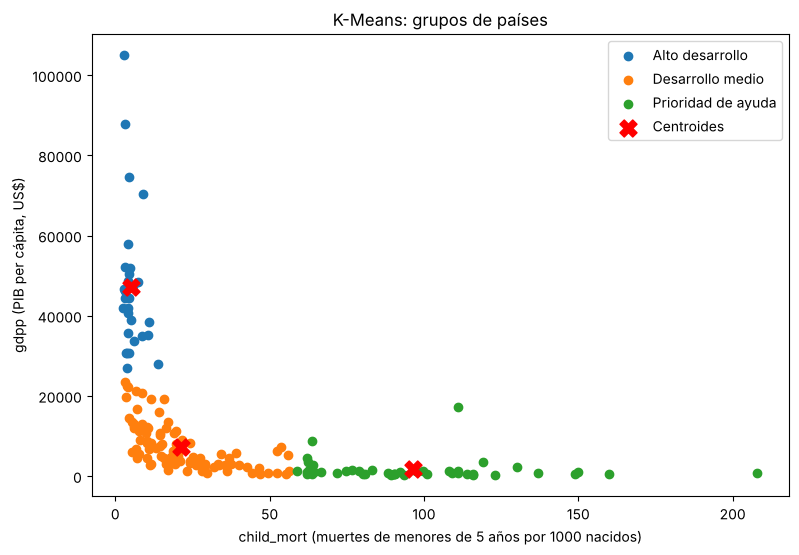

In [20]:
# Gráfico final con los grupos
plt.figure(figsize=(9, 6))
for c in orden:
    pts = X[labels == c]
    plt.scatter(pts[:, 0], pts[:, 1], label=nombres[c])
cent_orig = scaler.inverse_transform(centroids)
plt.scatter(cent_orig[:, 0], cent_orig[:, 1], c='red', marker='X', s=150, label="Centroides")
plt.xlabel('child_mort (muertes de menores de 5 años por 1000 nacidos)')
plt.ylabel('gdpp (PIB per cápita, US$)')
plt.title('K-Means: grupos de países')
plt.legend()
plt.savefig("imagenes/04_grupos.png", dpi=150, bbox_inches="tight")
plt.show()